<h1 align="center">E-Commerce Customer Segmentation</h1>
<h3 align="center"> K-Means Segmentation</h3>

**Project:** E-Commerce Customer Segmentation: RFM and K-Means Analysis of Who Drives, and Who Threatens, Revenue

This notebook answers **Objective 1** of the [analysis charter](../02_documentation/analysis_charter.md): *"Beyond Silver, Gold and Platinum, who are our customers really?"*

Notebook 2 grouped customers by Recency, Frequency and Monetary value only. Here, K-means groups them on a wider set of behaviours: how recently and how often they buy, how big their baskets are, how much they rely on coupons, how they pay, and what they buy. The result is compared with the RFM segments from Notebook 2.

**Steps**

We want to:

1. Prepare the clustering features (decisions carried over from Notebook 1).
2. Compare model versions: three ways of measuring Recency, and with or without Electronics share, cancel/return rate, and coupon and payment behaviour.
3. Choose the number of clusters using four tests: the elbow, silhouette score, stability and business usefulness.
4. Measure which features actually separate the clusters.
5. Profile and name the clusters.
6. Compare them with the RFM segments and the loyalty tiers.
7. Save the segments and the model settings for Notebook 4.

**Source tags.** Figures from earlier notebooks are tagged *[Notebook 1]* or *[Notebook 2]*. Every other figure is calculated here and is cited elsewhere as *[Notebook 3]*.

| Input | Output |
|---|---|
| `01_data/output/customer_features_full.csv` *[Notebook 1]* | `01_data/output/kmeans_segments_full.csv` |
| `01_data/output/rfm_scores_full.csv` *[Notebook 2]* | `01_data/output/kmeans_model_config.json` |
| | `04_report/figures/nb03_*.png` |

## 1. Load the customers to cluster

The 66 customers with no valid orders are excluded, as in Notebook 2, because they have no basket or category mix *[Notebook 1, Section 4.1]*.

In [1]:
# pathlib: build file paths that work on Windows, macOS and Linux
from pathlib import Path

# pandas: read and reshape the customer tables
import pandas as pd

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

OUTPUT_DIR = Path("../01_data/output")
features = pd.read_csv(OUTPUT_DIR / "customer_features_full.csv", index_col="customer_id")
customers = features[features.frequency > 0].copy()
rfm = pd.read_csv(OUTPUT_DIR / "rfm_scores_full.csv", index_col="customer_id")
print(f"Customers to cluster: {len(customers):,} (excluded with no valid orders: {len(features) - len(customers)})")
assert customers.index.equals(rfm.index), "Customer list differs from NB02"

Customers to cluster: 39,848 (excluded with no valid orders: 66)


## 2. Clustering features

Decisions carried over from Notebook 1:

- **Frequency and AOV are used instead of Monetary**, with a plain log, so log Monetary = log Frequency + log AOV exactly. Spend is represented without being counted twice *[Notebook 1, Section 4.4]*.
- **Customer tier, age group, state and gender are not used.** They describe the clusters afterwards.
- **Percentage-coupon share and digital share are not used.** The first is undefined for customers who never used a coupon, and the second mirrors COD share *[Notebook 1, Section 4.3]*.

Three choices are left open and tested in Section 3: how to measure Recency, whether to keep Electronics share (it overlaps with AOV, ρ = 0.77), and whether to add cancel/return rate.

In [2]:
# numpy: log and square-root transformations
import numpy as np

candidates = pd.DataFrame({
    "recency_raw": customers.recency_days,
    "recency_log": np.log1p(customers.recency_days),   # log(1 + days): some customers ordered on the snapshot day (0 days)
    "recency_sqrt": np.sqrt(customers.recency_days),
    "log_frequency": np.log(customers.frequency),
    "log_aov": np.log(customers.aov),
    "coupon_rate": customers.coupon_rate,
    "cod_share": customers.cod_share,
    "electronics_share": customers.electronics_share,
    "category_breadth": customers.category_breadth,
    "cancel_return_rate": customers.cancel_return_rate,
}, index=customers.index)

# The identity behind Option C, checked on the data
assert np.allclose(np.log(customers.monetary), candidates.log_frequency + candidates.log_aov)
assert candidates.notna().all().all()
candidates.describe().T[["mean", "std", "min", "50%", "max"]]

,mean,std,min,50%,max
recency_raw,119.553,115.959,0.000,83.000,758.000
recency_log,4.247,1.217,0.000,4.431,6.632
recency_sqrt,9.699,5.048,0.000,9.110,27.532
log_frequency,1.630,0.480,0.000,1.609,2.890
log_aov,9.702,0.984,4.541,9.891,12.742
coupon_rate,0.201,0.178,0.000,0.200,1.000
cod_share,0.328,0.218,0.000,0.333,1.000
electronics_share,0.268,0.242,0.000,0.250,1.000
category_breadth,2.549,0.607,1.000,3.000,3.000
cancel_return_rate,0.099,0.128,0.000,0.000,0.750


### Scaling

K-means measures distance between customers. Without scaling, a feature measured in hundreds of days (Recency) would outweigh one measured between 0 and 1 (coupon rate). Each feature is therefore rescaled to a mean of 0 and a standard deviation of 1, so every feature counts equally.

In [3]:
# scikit-learn StandardScaler: rescale each feature to mean 0, standard deviation 1
from sklearn.preprocessing import StandardScaler


def scale(columns):
    return StandardScaler().fit_transform(candidates[columns])

## 3. Comparing model versions

Six versions of the feature set are compared on the **silhouette score** for 2 to 8 clusters. The silhouette score measures how much closer each customer is to its own cluster than to the next nearest one:

- below 0.25: weak structure, the clusters are slices of a continuum rather than natural groups;
- 0.25–0.50: moderate structure;
- above 0.50: strong, well-separated groups.

The silhouette score is calculated on a fixed random sample of 10,000 customers, because the full calculation compares every pair of customers and is slow on 39,848.

| Version | Recency | Other features | Tests |
|---|---|---|---|
| A | Raw days | Frequency, AOV, coupon rate, COD share, Electronics share, category breadth | The baseline set agreed in the charter |
| B | Log days | Same as A | Does taming Recency's long tail help? |
| C | Square-root days | Same as A | A milder transformation |
| D | Raw days | A without Electronics share | Does the overlap with AOV distort the clusters? |
| E | Raw days | A plus cancel/return rate | Does order failure add a useful dimension? |
| F | Raw days | A without coupon rate and COD share | How much do coupon and payment behaviour add? |

In [4]:
# scikit-learn KMeans: the clustering algorithm; silhouette_score: how well separated the clusters are
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

SEED = 42
BEHAVIOUR = ["log_frequency", "log_aov", "coupon_rate", "cod_share", "electronics_share", "category_breadth"]
VERSIONS = {
    "A: raw Recency": ["recency_raw"] + BEHAVIOUR,
    "B: log Recency": ["recency_log"] + BEHAVIOUR,
    "C: square-root Recency": ["recency_sqrt"] + BEHAVIOUR,
    "D: A without Electronics share": ["recency_raw"] + [f for f in BEHAVIOUR if f != "electronics_share"],
    "E: A plus cancel/return rate": ["recency_raw"] + BEHAVIOUR + ["cancel_return_rate"],
    "F: A without coupon and COD": ["recency_raw"] + [f for f in BEHAVIOUR if f not in ("coupon_rate", "cod_share")],
}
K_RANGE = range(2, 9)
sample = np.random.default_rng(SEED).choice(len(candidates), size=10_000, replace=False)

silhouettes = {}
for name, cols in VERSIONS.items():
    X = scale(cols)
    silhouettes[name] = {k: silhouette_score(X[sample], KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X)[sample])
                         for k in K_RANGE}
silhouette_table = pd.DataFrame(silhouettes).T
silhouette_table.columns = [f"k={k}" for k in K_RANGE]
# pandas Styler.background_gradient shades the cells (it uses matplotlib behind the scenes)
silhouette_table.style.format("{:.3f}").background_gradient(axis=None, cmap="Blues")

,k=2,k=3,k=4,k=5,k=6,k=7,k=8
A: raw Recency,0.215,0.223,0.172,0.158,0.144,0.150,0.147
B: log Recency,0.207,0.210,0.161,0.151,0.151,0.136,0.140
C: square-root Recency,0.210,0.214,0.162,0.135,0.137,0.138,0.138
D: A without Electronics share,0.264,0.207,0.176,0.158,0.160,0.162,0.153
E: A plus cancel/return rate,0.244,0.203,0.145,0.144,0.134,0.122,0.122
F: A without coupon and COD,0.324,0.313,0.260,0.251,0.264,0.267,0.268


**Findings:**

- **Every version shows weak structure.** No version of the agreed feature set (A–E) reaches a silhouette score of 0.25 at 4 or more clusters. The customers form a continuum, not naturally separate groups. K-means still divides that continuum into consistent, usable slices (stability is tested in Section 4), but the boundaries between segments are soft. This is the honest result the charter asked to report, and it fits the first project's note that the data is likely synthetic *[Report §5]*.
- **Recency: raw days are kept (version A).** Raw days score as well as or better than the log and square-root versions at 4, 5 and 7 clusters (for example 0.172 against 0.161 and 0.162 at k = 4). The log version is only ahead at k = 6. Raw days are also the easiest to explain ("days since last order").
- **Electronics share is kept.** Removing it (D) changes the scores only slightly (0.158–0.176 against 0.144–0.172 for A at 4–7 clusters), so its overlap with AOV does not distort the clusters, and it is a key business dimension for Objective 5.
- **Cancel/return rate is left out.** Adding it (E) lowers the score at every k from 3 upwards (for example 0.122 against 0.150 at k = 7). Order failure looks random across customers and only blurs the clusters.
- **Coupon rate and COD share are kept, at a cost.** Without them (F), the silhouette rises to 0.251–0.267 at 4–7 clusters, the only version with moderate structure. They are kept because the project brief requires coupon use and payment mode in the model, and because coupon rate creates a distinct segment that Objective 4 needs (Section 6). The cost is noted here so a reader can see it.

## 4. Choosing the number of clusters

The chosen feature set is version A. Four tests are applied for k = 2 to 10:

1. **Elbow:** within-cluster spread (inertia). Each extra cluster reduces it; the point where the gains flatten suggests a natural number.
2. **Silhouette score**, as above.
3. **Stability:** the model is refitted on 50 bootstrap samples (customers drawn at random with replacement). Each refitted model assigns every customer to a cluster, and the assignments are compared with the original model using the **adjusted Rand index (ARI)**: 1 means identical groupings, 0 means no better than chance. The charter's target is a mean ARI of at least 0.8.
4. **Usefulness:** every cluster holds at least 3% of customers.

In [5]:
# scikit-learn adjusted_rand_score: agreement between two groupings of the same customers
from sklearn.metrics import adjusted_rand_score

FEATURES = VERSIONS["A: raw Recency"]
X = scale(FEATURES)
N_BOOT = 50

rows = []
for k in range(2, 11):
    reference = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    rng = np.random.default_rng(k)
    aris = []
    for b in range(N_BOOT):
        boot = rng.choice(len(X), size=len(X), replace=True)
        refit = KMeans(n_clusters=k, n_init=10, random_state=b).fit(X[boot])
        aris.append(adjusted_rand_score(reference.labels_, refit.predict(X)))
    sizes = np.bincount(reference.labels_) / len(X)
    rows.append({"k": k, "inertia": reference.inertia_,
                 "silhouette": silhouette_score(X[sample], reference.labels_[sample]),
                 "stability_mean_ari": np.mean(aris), "stability_min_ari": np.min(aris),
                 "smallest_cluster": sizes.min()})
k_table = pd.DataFrame(rows).set_index("k")
k_table["meets_charter"] = (k_table.stability_mean_ari >= 0.8) & (k_table.smallest_cluster >= 0.03) & k_table.index.isin(range(4, 8))
k_table.style.format({"inertia": "{:,.0f}", "silhouette": "{:.3f}", "stability_mean_ari": "{:.3f}",
                      "stability_min_ari": "{:.3f}", "smallest_cluster": "{:.1%}"})

,inertia,silhouette,stability_mean_ari,stability_min_ari,smallest_cluster,meets_charter
k,,,,,,
2,"226,608",0.215,0.776,0.292,35.2%,False
3,"193,586",0.223,0.984,0.958,19.2%,False
4,"175,262",0.172,0.970,0.922,12.5%,True
5,"163,995",0.158,0.977,0.924,7.1%,True
6,"154,635",0.144,0.931,0.594,6.5%,True
7,"146,430",0.150,0.952,0.899,5.0%,True
8,"140,427",0.147,0.870,0.576,4.0%,False
9,"135,060",0.140,0.607,0.428,3.5%,False
10,"129,467",0.139,0.863,0.585,3.4%,False


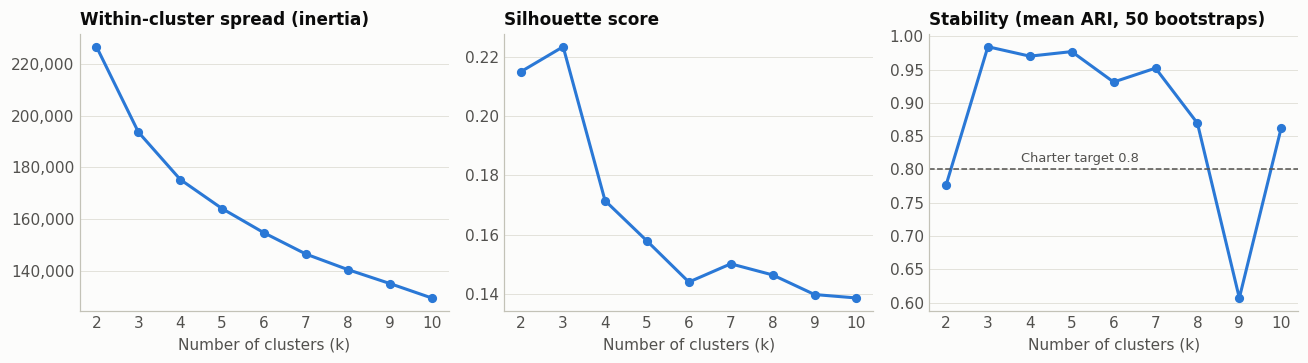

In [6]:
# matplotlib: draw the charts; FuncFormatter formats axis numbers
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# plot_style.py (this folder): shared colours and chart defaults for every notebook
import plot_style as ps
ps.apply()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
panels = [("inertia", "Within-cluster spread (inertia)", "{x:,.0f}"),
          ("silhouette", "Silhouette score", "{x:.2f}"),
          ("stability_mean_ari", "Stability (mean ARI, 50 bootstraps)", "{x:.2f}")]
for ax, (col, title, fmt) in zip(axes, panels):
    ax.plot(k_table.index, k_table[col], color=ps.SERIES[0], marker="o", markersize=5)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Number of clusters (k)")
    ax.set_xticks(k_table.index)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _, f=fmt: f.format(x=x)))
axes[2].axhline(0.8, color=ps.TEXT_SECONDARY, linewidth=1, linestyle="--")
axes[2].annotate("Charter target 0.8", xy=(3.8, 0.8), xytext=(0, 5), textcoords="offset points",
                 fontsize=8.5, color=ps.TEXT_SECONDARY)
fig.tight_layout()
ps.save(fig, "nb03_choosing_k")
plt.show()

### What changes between 5, 6 and 7 clusters?

The statistics above narrow the choice to 4–7 clusters. To see what each extra cluster adds in business terms, the clusters for k = 5, 6 and 7 are listed below, sorted by how long ago their customers last ordered.

In [7]:
compare_k = []
for k in (5, 6, 7):
    labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X)
    summary_k = customers.groupby(labels).agg(customers=("monetary", "count"), median_recency=("recency_days", "median"),
                                              median_aov=("aov", "median"), coupon_rate=("coupon_rate", "mean"),
                                              electronics_share=("electronics_share", "mean"))
    summary_k = summary_k.sort_values("median_recency", ascending=False).reset_index(drop=True)
    summary_k.insert(0, "k", k)
    compare_k.append(summary_k)
pd.concat(compare_k).style.format({"customers": "{:,.0f}", "median_recency": "{:,.0f}", "median_aov": "₹{:,.0f}",
                                   "coupon_rate": "{:.1%}", "electronics_share": "{:.1%}"}).hide(axis="index")

k,customers,median_recency,median_aov,coupon_rate,electronics_share
5,"2,814",387,"₹14,771",21.6%,21.2%
5,"6,058",95,"₹38,377",20.4%,58.7%
5,"6,763",87,"₹6,676",20.0%,1.8%
5,"15,576",69,"₹27,872",20.0%,36.3%
5,"8,637",67,"₹9,633",19.8%,8.6%
6,"2,588",393,"₹13,964",20.8%,19.8%
6,"5,559",100,"₹39,673",18.1%,60.5%
6,"6,384",89,"₹6,305",19.2%,1.5%
6,"6,346",80,"₹24,166",41.2%,31.7%
6,"7,300",66,"₹8,915",17.4%,6.6%


**Findings:**

- **The inertia curve has no sharp elbow.** It flattens gradually, which is typical of data without strong natural groups.
- **The silhouette score falls after k = 3** and is flat at 0.139–0.172 from 4 to 10 clusters.
- **Stability is high from 3 to 7 clusters** (mean ARI 0.931–0.984) and becomes erratic from 8 upwards (0.607–0.870). Two clusters are unstable (mean 0.776).
- **k = 4, 5, 6 and 7 all meet the charter's tests** (mean ARI at least 0.8, smallest cluster at least 3%, 4–7 clusters). k = 6 is the weakest of them: its mean ARI is 0.931, but one resample fell to 0.594, meaning the 6-cluster solution sometimes splits customers in a different way.

**What each extra cluster adds** (the table above):

- At **k = 5**, coupon rate is about 20% in every cluster, so no segment captures coupon behaviour, and there is one lapsed group.
- At **k = 6**, a **coupon-led** group appears (coupon rate about 41%).
- At **k = 7**, the lapsed customers split in two: one group with a median AOV of about ₹25,000 and one with about ₹3,000. These need very different treatment: one is worth a win-back campaign, the other is not.

**Decision: k = 7.** It keeps the coupon-led segment that Objective 4 needs, separates valuable lapsed customers from low-value ones for Objective 3, and is more stable than k = 6 (mean ARI 0.952, worst resample 0.899) with a slightly higher silhouette score (0.150 against 0.144). Its smallest cluster holds 5.0% of customers.

In [8]:
K = 7
model = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X)
customers["cluster"] = model.labels_
print(f"Final model: k = {K}, features = {FEATURES}")
print(customers.cluster.value_counts().sort_index().to_string())

Final model: k = 7, features = ['recency_raw', 'log_frequency', 'log_aov', 'coupon_rate', 'cod_share', 'electronics_share', 'category_breadth']
cluster
0     6806
1     5068
2     3177
3     6042
4     5626
5    11130
6     1999


## 5. Which features separate the clusters?

For each feature, **η² (eta squared)** is the share of its variation explained by which cluster a customer belongs to. A value near 1 means the clusters differ sharply on that feature; a value near 0 means the feature looks the same in every cluster.

In [9]:
scaled = pd.DataFrame(X, columns=FEATURES, index=customers.index)


def eta_squared(values, groups):
    between = values.groupby(groups).agg(["count", "mean"])
    ss_between = (between["count"] * (between["mean"] - values.mean()) ** 2).sum()
    return ss_between / ((values - values.mean()) ** 2).sum()


eta = pd.Series({f: eta_squared(scaled[f], customers.cluster) for f in FEATURES}).sort_values(ascending=False)
eta.rename("eta_squared").to_frame().style.format("{:.3f}").bar(color=ps.BLUE_RAMP[2], vmin=0, vmax=1)

,eta_squared
category_breadth,0.774
electronics_share,0.658
log_aov,0.557
recency_raw,0.499
log_frequency,0.458
coupon_rate,0.287
cod_share,0.092


**Finding:** the clusters are separated mainly by **what and how customers buy**:

- **Category breadth** (η² = 0.774) and **Electronics share** (0.658) separate them most.
- **AOV** (0.557), **Recency** (0.499) and **Frequency** (0.458) follow.
- **Coupon rate** (0.287) separates them moderately, almost entirely through the Coupon-led segment.
- **COD share** (0.092) barely separates them at all. Only the Frequent everyday shoppers stand out on it (Section 6).

Recency is only the fourth strongest feature. That matters for Section 7: K-means groups customers by their buying style more than by how recently they bought.

## 6. Cluster profiles and names

In [10]:
profile = customers.groupby("cluster").agg(
    customers=("monetary", "count"),
    revenue=("monetary", "sum"),
    recency_days=("recency_days", "median"),
    frequency=("frequency", "median"),
    aov=("aov", "median"),
    monetary=("monetary", "median"),
    coupon_rate=("coupon_rate", "mean"),
    cod_share=("cod_share", "mean"),
    electronics_share=("electronics_share", "mean"),
    category_breadth=("category_breadth", "mean"),
)
profile.insert(1, "share_of_customers", profile.customers / profile.customers.sum())
profile.insert(3, "share_of_revenue", profile.revenue / profile.revenue.sum())
PROFILE_FORMAT = {"customers": "{:,.0f}", "share_of_customers": "{:.1%}", "revenue": lambda v: f"₹{v / 1e6:,.1f} M",
                  "share_of_revenue": "{:.1%}", "recency_days": "{:,.0f}", "frequency": "{:,.0f}", "aov": "₹{:,.0f}",
                  "monetary": "₹{:,.0f}", "coupon_rate": "{:.1%}", "cod_share": "{:.1%}",
                  "electronics_share": "{:.1%}", "category_breadth": "{:.2f}"}
profile.style.format(PROFILE_FORMAT)

,customers,share_of_customers,revenue,share_of_revenue,recency_days,frequency,aov,monetary,coupon_rate,cod_share,electronics_share,category_breadth
cluster,,,,,,,,,,,,
0,"6,806",17.1%,₹449.0 M,8.4%,67,7,"₹8,658","₹56,897",17.5%,45.7%,6.7%,2.99
1,"5,068",12.7%,₹941.7 M,17.7%,93,4,"₹40,339","₹158,868",18.5%,28.8%,62.2%,1.88
2,"3,177",8.0%,₹378.0 M,7.1%,328,4,"₹25,204","₹99,470",16.4%,30.0%,34.2%,2.52
3,"6,042",15.2%,₹252.6 M,4.7%,75,4,"₹7,968","₹32,974",18.3%,35.6%,2.3%,1.93
4,"5,626",14.1%,₹906.9 M,17.0%,76,6,"₹23,846","₹140,326",42.6%,29.2%,31.5%,2.87
5,"11,130",27.9%,"₹2,377.7 M",44.6%,58,7,"₹27,834","₹190,443",12.5%,27.1%,36.4%,2.97
6,"1,999",5.0%,₹22.2 M,0.4%,284,2,"₹3,118","₹6,597",23.9%,36.3%,1.2%,1.37


### Naming the clusters

K-means numbers its clusters arbitrarily, so names are assigned by **rules based on each cluster's profile**, not by cluster number. The rules are applied in order, each to the clusters not yet named, and the code checks that every rule picks a different cluster:

| Order | Rule | Name |
|---|---|---|
| 1 | The two clusters with the longest median time since last order; the one with the higher median AOV | Lapsed high-value customers |
| 2 | The other of those two | Lapsed light buyers |
| 3 | Highest average coupon rate | Coupon-led buyers |
| 4 | Highest average Electronics share | Big-ticket Electronics buyers |
| 5 | Highest median AOV of those left | Core high-value regulars |
| 6 | Highest median Frequency of those left | Frequent everyday shoppers |
| 7 | The remaining cluster | Occasional light shoppers |

In [11]:
remaining = list(profile.index)
names = {}

# Rules 1-2: the two least recent clusters, split by basket size
lapsed = profile.recency_days.nlargest(2).index
names[profile.loc[lapsed, "aov"].idxmax()] = "Lapsed high-value customers"
names[profile.loc[lapsed, "aov"].idxmin()] = "Lapsed light buyers"
remaining = [c for c in remaining if c not in lapsed]

# Rules 3-6: each picks one of the clusters not yet named
for name, column, pick in [("Coupon-led buyers", "coupon_rate", "max"),
                           ("Big-ticket Electronics buyers", "electronics_share", "max"),
                           ("Core high-value regulars", "aov", "max"),
                           ("Frequent everyday shoppers", "frequency", "max")]:
    chosen = getattr(profile.loc[remaining, column], f"idx{pick}")()
    names[chosen] = name
    remaining.remove(chosen)
names[remaining[0]] = "Occasional light shoppers"
assert len(set(names.values())) == K

SEGMENT_ORDER = ["Core high-value regulars", "Big-ticket Electronics buyers", "Coupon-led buyers",
                 "Frequent everyday shoppers", "Occasional light shoppers",
                 "Lapsed high-value customers", "Lapsed light buyers"]
customers["kmeans_segment"] = pd.Categorical(customers.cluster.map(names), categories=SEGMENT_ORDER, ordered=True)
profile = profile.rename(index=names).reindex(SEGMENT_ORDER)
profile.index.name = "kmeans_segment"
profile.style.format(PROFILE_FORMAT)

,customers,share_of_customers,revenue,share_of_revenue,recency_days,frequency,aov,monetary,coupon_rate,cod_share,electronics_share,category_breadth
kmeans_segment,,,,,,,,,,,,
Core high-value regulars,"11,130",27.9%,"₹2,377.7 M",44.6%,58,7,"₹27,834","₹190,443",12.5%,27.1%,36.4%,2.97
Big-ticket Electronics buyers,"5,068",12.7%,₹941.7 M,17.7%,93,4,"₹40,339","₹158,868",18.5%,28.8%,62.2%,1.88
Coupon-led buyers,"5,626",14.1%,₹906.9 M,17.0%,76,6,"₹23,846","₹140,326",42.6%,29.2%,31.5%,2.87
Frequent everyday shoppers,"6,806",17.1%,₹449.0 M,8.4%,67,7,"₹8,658","₹56,897",17.5%,45.7%,6.7%,2.99
Occasional light shoppers,"6,042",15.2%,₹252.6 M,4.7%,75,4,"₹7,968","₹32,974",18.3%,35.6%,2.3%,1.93
Lapsed high-value customers,"3,177",8.0%,₹378.0 M,7.1%,328,4,"₹25,204","₹99,470",16.4%,30.0%,34.2%,2.52
Lapsed light buyers,"1,999",5.0%,₹22.2 M,0.4%,284,2,"₹3,118","₹6,597",23.9%,36.3%,1.2%,1.37


### How each segment differs from the average customer

Each cell shows the segment's average on a feature, in standard deviations from the average customer (the scaled values K-means used). Red is above average, blue below.

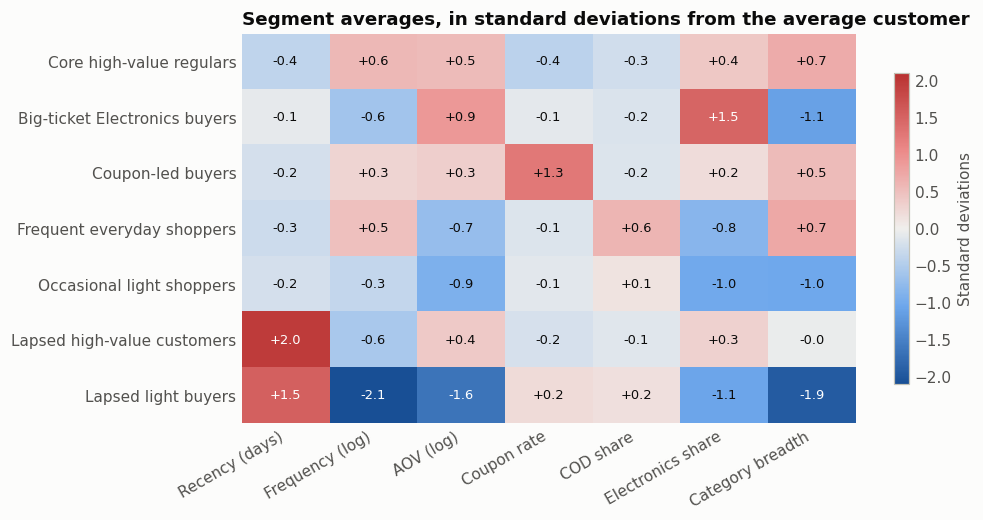

In [12]:
z_means = scaled.groupby(customers.kmeans_segment, observed=True).mean().reindex(SEGMENT_ORDER)
feature_labels = {"recency_raw": "Recency (days)", "log_frequency": "Frequency (log)", "log_aov": "AOV (log)",
                  "coupon_rate": "Coupon rate", "cod_share": "COD share", "electronics_share": "Electronics share",
                  "category_breadth": "Category breadth"}

fig, ax = plt.subplots(figsize=(9, 4.6))
limit = np.abs(z_means.values).max()
im = ax.imshow(z_means.values, cmap=ps.DIVERGING, vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(len(FEATURES)), [feature_labels[f] for f in FEATURES], rotation=30, ha="right")
ax.set_yticks(range(len(SEGMENT_ORDER)), SEGMENT_ORDER)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(z_means.shape[0]):
    for j in range(z_means.shape[1]):
        v = z_means.values[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=8.5,
                color="white" if abs(v) > limit * 0.6 else ps.TEXT_PRIMARY)
ax.set_title("Segment averages, in standard deviations from the average customer")
fig.colorbar(im, ax=ax, shrink=0.8, label="Standard deviations")
ps.save(fig, "nb03_segment_profiles")
plt.show()

**The seven segments** (valid-order revenue, Jun 2024 – Jun 2026):

| Segment | Customers | Revenue | What defines them |
|---|---|---|---|
| **Core high-value regulars** | 11,130 (27.9%) | ₹2,377.7 M (44.6%) | The most recent buyers (median 58 days) with a median of 7 orders at ₹27,834 each, across 3 categories. The lowest coupon use (12.5%) |
| **Big-ticket Electronics buyers** | 5,068 (12.7%) | ₹941.7 M (17.7%) | The largest baskets (median ₹40,339) and 62.2% of orders in Electronics, but only 4 orders across fewer than 2 categories on average |
| **Coupon-led buyers** | 5,626 (14.1%) | ₹906.9 M (17.0%) | A coupon on 42.6% of orders, against 12.5%–23.9% in other segments. Otherwise they buy much like the core regulars (6 orders, ₹23,846 AOV) |
| **Frequent everyday shoppers** | 6,806 (17.1%) | ₹449.0 M (8.4%) | 7 orders but small baskets (₹8,658), almost no Electronics (6.7%), and the highest cash-on-delivery share (45.7%) |
| **Occasional light shoppers** | 6,042 (15.2%) | ₹252.6 M (4.7%) | 4 orders, small baskets (₹7,968), almost no Electronics (2.3%), fewer than 2 categories |
| **Lapsed high-value customers** | 3,177 (8.0%) | ₹378.0 M (7.1%) | Median 328 days since last order, but a mid-to-high basket (₹25,204) and ₹99,470 median spend before they went quiet |
| **Lapsed light buyers** | 1,999 (5.0%) | ₹22.2 M (0.4%) | Median 284 days since last order, 2 orders, ₹3,118 baskets |

The first three segments are 54.7% of customers and produce 79.3% of revenue.

### A two-dimensional view of the segments

PCA (principal component analysis) compresses the seven scaled features into the two directions that capture the most variation, so customers can be plotted on a flat map. Each panel highlights one segment against all other customers in grey. A random sample of 8,000 customers is plotted so the points stay readable.

Variation captured by the two PCA dimensions: 52.5% (28.8% + 23.7%)


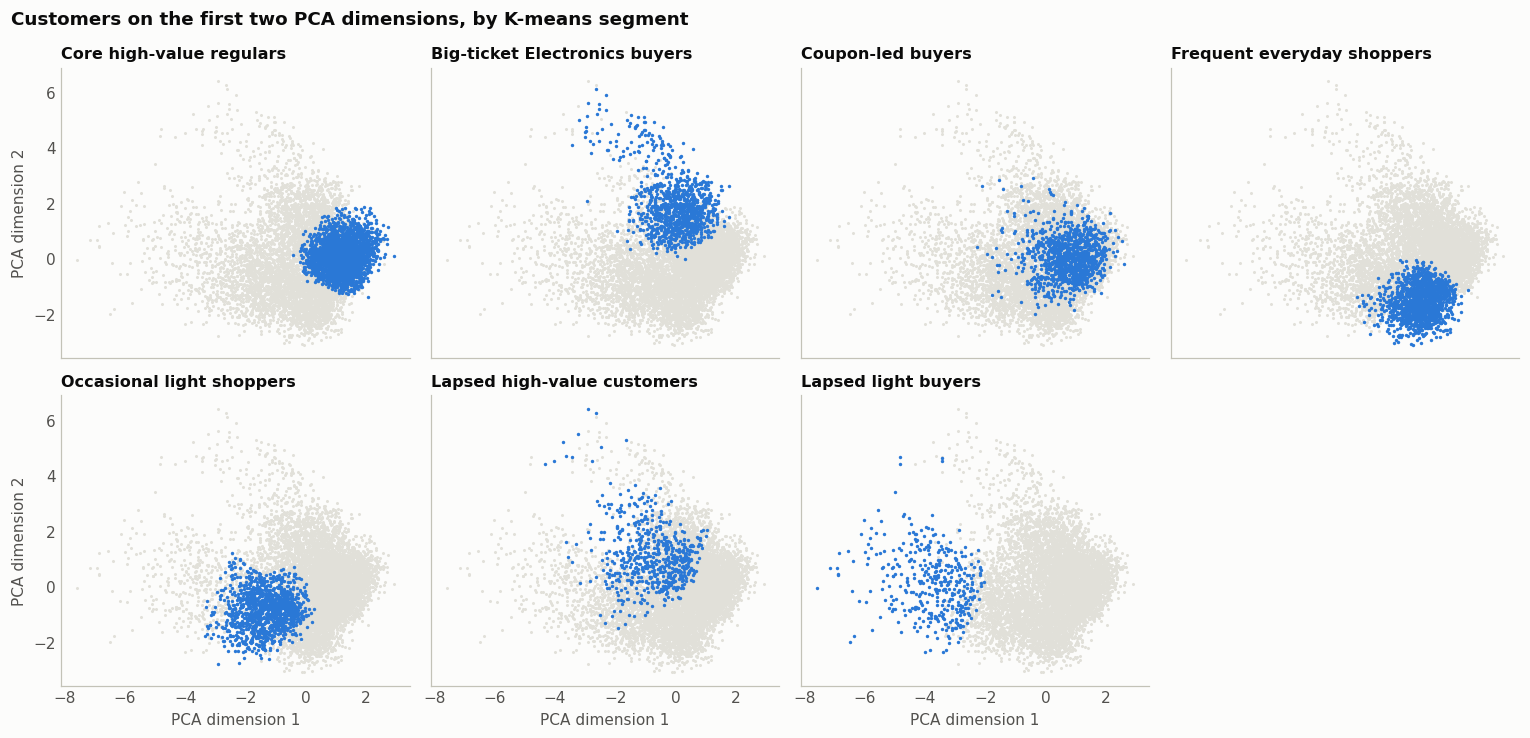

In [13]:
# scikit-learn PCA: project the seven scaled features onto two dimensions for plotting
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=SEED).fit(X)
coords = pca.transform(X)
print(f"Variation captured by the two PCA dimensions: {pca.explained_variance_ratio_.sum():.1%} "
      f"({pca.explained_variance_ratio_[0]:.1%} + {pca.explained_variance_ratio_[1]:.1%})")

plot_idx = np.random.default_rng(SEED).choice(len(X), size=8_000, replace=False)
seg = customers.kmeans_segment.to_numpy()[plot_idx]
pts = coords[plot_idx]

fig, axes = plt.subplots(2, 4, figsize=(14, 6.8), sharex=True, sharey=True)
for ax, name in zip(axes.flat, SEGMENT_ORDER):
    mask = seg == name
    ax.scatter(pts[~mask, 0], pts[~mask, 1], s=4, color=ps.GRID, linewidths=0)
    ax.scatter(pts[mask, 0], pts[mask, 1], s=5, color=ps.SERIES[0], linewidths=0)
    ax.set_title(name, fontsize=10.5)
    ax.grid(False)
axes.flat[-1].set_visible(False)  # 7 segments, 8 panels
for ax in axes[1]:
    ax.set_xlabel("PCA dimension 1")
for ax in axes[:, 0]:
    ax.set_ylabel("PCA dimension 2")
fig.suptitle("Customers on the first two PCA dimensions, by K-means segment", x=0.01, ha="left",
             fontsize=12, fontweight="semibold")
fig.tight_layout()
ps.save(fig, "nb03_pca_map")
plt.show()

**Finding:** the two PCA dimensions capture 52.5% of the variation in the seven features, so the map is a simplified view. The segments occupy distinct regions but border each other with no empty space in between, which is the visual form of the weak silhouette scores in Section 3. **Lapsed light buyers** sit furthest from the main body of customers, set apart by long absence, few orders and small baskets together. **Lapsed high-value customers** overlap the main body much more: apart from their long absence, they buy much like active customers. Big-ticket Electronics buyers stretch upwards into their own region, driven by Electronics share and basket size.

## 7. Comparison with the RFM segments (NB02)

How do the six K-means segments relate to the seven RFM segments? Each row of the table shows how an RFM segment's customers are spread across the K-means segments.

In [14]:
RFM_ORDER = ["Champions", "Loyal", "Recent low spenders", "Needs attention", "At risk", "About to sleep", "Hibernating"]
customers["rfm_segment"] = pd.Categorical(rfm.rfm_segment, categories=RFM_ORDER, ordered=True)

crosstab = pd.crosstab(customers.rfm_segment, customers.kmeans_segment, normalize="index")
display(crosstab.style.format("{:.0%}").background_gradient(axis=None, cmap="Blues"))
ari_rfm = adjusted_rand_score(customers.rfm_segment, customers.kmeans_segment)
print(f"Agreement between RFM and K-means segments (adjusted Rand index): {ari_rfm:.3f}")

kmeans_segment,Core high-value regulars,Big-ticket Electronics buyers,Coupon-led buyers,Frequent everyday shoppers,Occasional light shoppers,Lapsed high-value customers,Lapsed light buyers
rfm_segment,,,,,,,
Champions,57%,8%,18%,15%,2%,0%,0%
Loyal,35%,15%,17%,24%,9%,0%,0%
Recent low spenders,11%,13%,10%,20%,43%,0%,3%
Needs attention,10%,15%,11%,19%,39%,0%,5%
At risk,44%,11%,20%,11%,2%,12%,0%
About to sleep,16%,20%,14%,19%,8%,23%,0%
Hibernating,4%,11%,7%,11%,22%,23%,23%


Agreement between RFM and K-means segments (adjusted Rand index): 0.099


In [15]:
at_risk = customers[customers.rfm_segment == "At risk"]
at_risk_split = at_risk.groupby("kmeans_segment", observed=True).agg(
    customers=("monetary", "count"), revenue=("monetary", "sum"), median_recency=("recency_days", "median"))
at_risk_split["share_of_at_risk"] = at_risk_split.customers / at_risk_split.customers.sum()
print(f"Notebook 2's At risk segment: {len(at_risk):,} customers")
at_risk_split.sort_values("customers", ascending=False).style.format(
    {"customers": "{:,.0f}", "revenue": lambda v: f"₹{v / 1e6:,.1f} M", "median_recency": "{:,.0f}", "share_of_at_risk": "{:.1%}"})

Notebook 2's At risk segment: 4,167 customers


,customers,revenue,median_recency,share_of_at_risk
kmeans_segment,,,,
Core high-value regulars,"1,823",₹449.5 M,155,43.7%
Coupon-led buyers,841,₹192.2 M,164,20.2%
Lapsed high-value customers,497,₹114.9 M,315,11.9%
Big-ticket Electronics buyers,459,₹140.4 M,167,11.0%
Frequent everyday shoppers,449,₹49.1 M,154,10.8%
Occasional light shoppers,98,₹11.3 M,166,2.4%


**Findings:**

- **The two methods group customers very differently** (adjusted Rand index 0.099). RFM sorts customers by *when* and *how much* they buy. K-means mainly sorts them by *what* and *how* they buy (Section 5).
- **They complement each other rather than compete.** The clearest example is Notebook 2's **At risk** segment (4,167 customers who spend like Champions but last ordered a median of 168 days ago *[Notebook 2]*). K-means spreads them across six segments:
  - 43.7% are **Core high-value regulars** by buying style, holding ₹449.5 M;
  - 20.2% are **Coupon-led buyers**;
  - only 11.9% fall in **Lapsed high-value customers**.
- **K-means only isolates very long absences as "lapsed".** The At risk customers placed in Lapsed high-value have a median of 315 days since their last order, against 154–167 days for those in the other segments. A gap of five or six months is not enough for K-means to separate a customer from others with the same buying style.

**Implication for the rest of the project:** the K-means segment says *what kind of customer* someone is; the RFM Recency score says *whether they are still buying*. The segment playbook (Notebook 6) is expected to use both together. For example, "a Core high-value regular who has not ordered for five months" needs a different message from "a Coupon-led buyer who has not ordered for five months". Notebook 4 will test which of the two methods better predicts who actually stopped buying.

## 8. Loyalty tiers within each segment

A first look at Objective 2 from the K-means side. The full tier analysis is in Notebook 4.

In [16]:
TIER_ORDER = ["Silver", "Gold", "Platinum"]
tier_mix = pd.crosstab(customers.kmeans_segment, customers.customer_tier, normalize="index")[TIER_ORDER]
overall = customers.customer_tier.value_counts(normalize=True).reindex(TIER_ORDER)
display(tier_mix.style.format("{:.1%}"))
print("All clustered customers:", ", ".join(f"{t} {overall[t]:.1%}" for t in TIER_ORDER))

customer_tier,Silver,Gold,Platinum
kmeans_segment,,,
Core high-value regulars,0.9%,3.7%,95.4%
Big-ticket Electronics buyers,4.0%,7.0%,89.0%
Coupon-led buyers,3.1%,10.8%,86.1%
Frequent everyday shoppers,16.1%,34.8%,49.1%
Occasional light shoppers,38.7%,33.8%,27.5%
Lapsed high-value customers,7.0%,18.9%,74.2%
Lapsed light buyers,83.9%,14.9%,1.3%


All clustered customers: Silver 14.6%, Gold 16.8%, Platinum 68.6%


**Findings:**

- **The three high-value segments are mostly Platinum:** Core high-value regulars 95.4%, Big-ticket Electronics buyers 89.0%, Coupon-led buyers 86.1%.
- **Lapsed high-value customers are 74.2% Platinum.** These customers hold the top tier while not having ordered for a median of 328 days.
- **Lapsed light buyers are 83.9% Silver**, and Occasional light shoppers are 38.7% Silver against 14.6% overall.
- **Frequent everyday shoppers are split:** 49.1% Platinum, 34.8% Gold and 16.1% Silver, despite similar buying behaviour. Customers who behave alike sit in very different tiers here, which Objective 2 looks at in Notebook 4.

## 9. Save the segments and the model settings

Notebook 4 will refit the same model on the calibration period (orders to 31 Dec 2025), so the settings are saved alongside the segments.

In [17]:
# json: save the model settings in a readable text format
import json

customers[["cluster", "kmeans_segment", "rfm_segment"]].to_csv(OUTPUT_DIR / "kmeans_segments_full.csv")

config = {
    "features": FEATURES,
    "transformations": {"recency_raw": "none (days)", "log_frequency": "natural log", "log_aov": "natural log",
                        "others": "none"},
    "scaling": "StandardScaler (mean 0, standard deviation 1), fitted on the clustered customers",
    "k": K,
    "n_init": 10,
    "random_state": SEED,
    "naming_rules": ["Lapsed high-value customers / Lapsed light buyers: the two clusters with the highest median "
                     "recency_days, split by higher / lower median aov",
                     "Coupon-led buyers: max mean coupon_rate",
                     "Big-ticket Electronics buyers: max mean electronics_share",
                     "Core high-value regulars: max median aov", "Frequent everyday shoppers: max median frequency",
                     "Occasional light shoppers: remaining cluster"],
    "scaler_mean": dict(zip(FEATURES, StandardScaler().fit(candidates[FEATURES]).mean_.round(6).tolist())),
    "cluster_names": {int(k): v for k, v in names.items()},
    "centroids_scaled": {names[i]: dict(zip(FEATURES, c.round(4).tolist())) for i, c in enumerate(model.cluster_centers_)},
}
(OUTPUT_DIR / "kmeans_model_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
for f in ["kmeans_segments_full.csv", "kmeans_model_config.json"]:
    print(f"Saved 01_data/output/{f}  ({(OUTPUT_DIR / f).stat().st_size / 1e3:,.0f} KB)")

Saved 01_data/output/kmeans_segments_full.csv  (2,088 KB)
Saved 01_data/output/kmeans_model_config.json  (3 KB)


## 10. Summary

| Question | Answer *[Notebook 3]* |
|---|---|
| Which features were used? | Recency (raw days), log Frequency, log AOV, coupon rate, COD share, Electronics share and category breadth, all scaled. Cancel/return rate was tested and left out |
| How strong is the structure? | Weak: silhouette 0.150 at k = 7. The customers form a continuum, and the segments are consistent slices of it rather than natural groups |
| How reliable are the segments? | Very stable: mean ARI 0.952 across 50 bootstrap refits, worst 0.899 |
| How many segments? | Seven: Core high-value regulars, Big-ticket Electronics buyers, Coupon-led buyers, Frequent everyday shoppers, Occasional light shoppers, Lapsed high-value customers and Lapsed light buyers |
| What separates them? | Mainly category breadth, Electronics share and AOV. Recency is fourth. Payment mode barely matters |
| Where is the value? | Core high-value regulars, Big-ticket Electronics buyers and Coupon-led buyers: 54.7% of customers, 79.3% of revenue |
| How do they relate to RFM? | Very differently (ARI 0.099). K-means describes buying style; RFM describes recency and value. They are used together from here on |

### What this sets up

- **Notebook 4** will fit the same model to the calibration period and tests how well the K-means and RFM segments predicted who stopped buying in Jan–Jun 2026. It will also complete the tier analysis (Objective 2).
- **Notebook 5** will study the Coupon-led buyers (Objective 4) and the Big-ticket Electronics buyers as the main cross-sell target (Objective 5).
- **Notebook 6** will combine each customer's K-means segment with their RFM Recency score in the action playbook.